In [1]:
import os
print(os.listdir("/kaggle/input"))

['datasets']


In [2]:
import os
print(os.listdir("/kaggle/input/datasets"))

['koushgh45', 'koushiki123890567']


In [3]:
import os
print(os.listdir("/kaggle/input/datasets/koushgh45"))

['crc-resnet50-baseline-weights', 'colorectal-cancer-histopathology']


In [4]:
import os
print(os.listdir("/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"))

['CRC-VAL-HE-7K', 'NCT-CRC-HE-100K']


In [5]:
import os

# This will search for the directory that contains your images
for root, dirs, files in os.walk("/kaggle/input"):
    if "NCT-CRC-HE-100K" in dirs:
        print(f"FOUND IT! Your path is: {os.path.join(root, 'NCT-CRC-HE-100K')}")
        break

FOUND IT! Your path is: /kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/NCT-CRC-HE-100K


In [6]:
import os
# We use the exact path confirmed by your os.walk search
confirmed_base = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"
print("Contents:", os.listdir(confirmed_base))

Contents: ['CRC-VAL-HE-7K', 'NCT-CRC-HE-100K']


In [7]:
import os
# Check what is inside the folder we are currently pointing to
print(os.listdir("/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/NCT-CRC-HE-100K/NCT-CRC-HE-100K"))

['MUC', 'TUM', 'DEB', 'BACK', 'ADI', 'MUS', 'NORM', 'LYM', 'STR']


In [8]:
import os

# Check the contents of the validation/external dataset
external_dir = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/CRC-VAL-HE-7K"
print("Contents of external dataset:", os.listdir(external_dir))

# If the list shows the same 9 class folders, your path is:
# /kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/CRC-VAL-HE-7K

Contents of external dataset: ['CRC-VAL-HE-7K']


In [9]:
import os
# Check the contents of the final nested folder
print(os.listdir("/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/CRC-VAL-HE-7K/CRC-VAL-HE-7K"))

['MUC', 'TUM', 'DEB', 'BACK', 'ADI', 'MUS', 'NORM', 'LYM', 'STR']


In [10]:
#import os
#import torch
#import torch.nn as nn
#import torch.optim as optim
#from torchvision import datasets, models, transforms
#from torch.utils.data import DataLoader, random_split

# ==========================================
# 4. SANITY CHECK: VERIFY PYTORCH SEES THE GPU
# ==========================================
#print("--- GPU Hardware Check ---")
#cuda_available = torch.cuda.is_available()
#print("Is CUDA available?:", cuda_available)
#if cuda_available:
    #print("Device Name:", torch.cuda.get_device_name(0))
    #device = torch.device("cuda")
#else:
    #print("❌ WARNING: GPU accelerator not detected. Please enable it in Kaggle settings.")
    #device = torch.device("cpu")

# ==========================================
# DATA CONFIGURATION & CONFIG PATHS
# ==========================================
#base_path = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"
#nct_dir = os.path.join(base_path, "NCT-CRC-HE-100K/NCT-CRC-HE-100K")

#BATCH_SIZE = 32
#TOTAL_EPOCHS = 30  # Setting back to 30 epochs for full convergence

# Base Transform (No Augmentations for Baseline)
#base_transform = transforms.Compose([
    #transforms.Resize((224, 224)),
    #transforms.ToTensor(),
    #transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
#])

# Load Dataset
#dataset = datasets.ImageFolder(root=nct_dir, transform=base_transform)

# Strict 3-Way Dataset Split (70% Train, 15% Val, 15% Test)
#total_len = len(dataset)
#train_size = int(0.70 * total_len)
#val_size = int(0.15 * total_len)
#test_size = total_len - train_size - val_size

#train_dataset, val_dataset, test_dataset = random_split(
    #dataset, [train_size, val_size, test_size], 
    #generator=torch.Generator().manual_seed(42) # Reproducible split
#)

# ==========================================
# 1 & 2. OPTIMIZED DATALOADERS (Workers + Pinning)
# ==========================================
# num_workers=4 uses 4 CPU processes to pre-fetch data in parallel
# pin_memory=True speeds up the data transfer from CPU RAM to GPU VRAM
#train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
#val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
#test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

#print(f"\nDataset split successfully:")
#print(f"  → Train samples: {len(train_dataset)}")
#print(f"  → Val samples: {len(val_dataset)}")
#print(f"  → Internal Test samples: {len(test_dataset)}")

# ==========================================
# MODEL SETUP & TRAINING
# ==========================================
# Initialize ResNet50 from scratch
#model = models.resnet50(weights=None)
#model.fc = nn.Linear(model.fc.in_features, 9)
#model = model.to(device)

#criterion = nn.CrossEntropyLoss()
#optimizer = optim.Adam(model.parameters(), lr=1e-3)

#print(f"\nStarting training loop for {TOTAL_EPOCHS} epochs...")
#for epoch in range(TOTAL_EPOCHS):
    #model.train()
    #running_loss = 0.0
    #for inputs, labels in train_loader:
        #inputs, labels = inputs.to(device), labels.to(device)
        
        #optimizer.zero_grad()
        #outputs = model(inputs)
        #loss = criterion(outputs, labels)
        #loss.backward()
        #optimizer.step()
        
        #running_loss += loss.item() * inputs.size(0)
        
    #epoch_loss = running_loss / len(train_loader.dataset)
    
    # Quick Validation Check
    #model.eval()
    #correct = 0
    #with torch.no_grad():
        #for inputs, labels in val_loader:
            #inputs, labels = inputs.to(device), labels.to(device)
            #outputs = model(inputs)
            #_, preds = torch.max(outputs, 1)
            #correct += torch.sum(preds == labels.data)
            
    #val_accuracy = correct.double() / len(val_loader.dataset)
    #print(f"Epoch {epoch+1}/{TOTAL_EPOCHS} | Train Loss: {epoch_loss:.4f} | Val Accuracy: {val_accuracy:.4f}")

# Save the strict baseline model parameters
#torch.save(model.state_dict(), "resnet50_strict_baseline.pth")
#print("\nTraining complete! Baseline model saved as 'resnet50_strict_baseline.pth'.")

In [11]:
import torch
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Recreate architecture
model = models.resnet50(weights=None)
num_classes = 9  # Adjust if your syllabus dataset uses a different number of classes
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
model.to(device)

# 2. Paste the copied path here to load the weights
weights_path = "/kaggle/input/datasets/koushgh45/crc-resnet50-baseline-weights/resnet50_strict_baseline.pth"
model.load_state_dict(torch.load(weights_path, map_location=device))

print("Model successfully loaded from Kaggle inputs!")

Model successfully loaded from Kaggle inputs!


In [12]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, random_split

# ==========================================
# 4. SANITY CHECK: VERIFY PYTORCH SEES THE GPU
# ==========================================
print("--- GPU Hardware Check ---")
cuda_available = torch.cuda.is_available()
print("Is CUDA available?:", cuda_available)
if cuda_available:
    print("Device Name:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    print("❌ WARNING: GPU accelerator not detected. Please enable it in Kaggle settings.")
    device = torch.device("cpu")

# ==========================================
# DATA CONFIGURATION & CONFIG PATHS
# ==========================================
base_path = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"
nct_dir = os.path.join(base_path, "NCT-CRC-HE-100K/NCT-CRC-HE-100K")

BATCH_SIZE = 32
TOTAL_EPOCHS = 30  # Setting back to 30 epochs for full convergence

# Base Transform (No Augmentations for Baseline)
base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load Dataset
dataset = datasets.ImageFolder(root=nct_dir, transform=base_transform)

# Strict 3-Way Dataset Split (70% Train, 15% Val, 15% Test)
total_len = len(dataset)
train_size = int(0.70 * total_len)
val_size = int(0.15 * total_len)
test_size = total_len - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset, [train_size, val_size, test_size], 
    generator=torch.Generator().manual_seed(42) # Reproducible split
)

# ==========================================
# 1 & 2. OPTIMIZED DATALOADERS (Workers + Pinning)
# ==========================================
# num_workers=4 uses 4 CPU processes to pre-fetch data in parallel
# pin_memory=True speeds up the data transfer from CPU RAM to GPU VRAM
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f"\nDataset split successfully:")
print(f"  → Train samples: {len(train_dataset)}")
print(f"  → Val samples: {len(val_dataset)}")
print(f"  → Internal Test samples: {len(test_dataset)}")


--- GPU Hardware Check ---
Is CUDA available?: True
Device Name: Tesla T4

Dataset split successfully:
  → Train samples: 70000
  → Val samples: 15000
  → Internal Test samples: 15000


In [13]:
#Internal test set evaluation

import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1. Verification function for evaluation
def evaluate_model(model, data_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    return np.array(all_labels), np.array(all_preds)

# 2. Load the trained baseline model weights
# Ensure 'device' is already defined from your training cell
model.load_state_dict(torch.load("/kaggle/input/datasets/koushgh45/crc-resnet50-baseline-weights/resnet50_strict_baseline.pth", map_location=device))
print("Strict baseline model weights loaded successfully.")

# 3. Run evaluation on the untouched Internal Test Set
print("Evaluating on Internal Test Set (15,000 images)...")
internal_labels, internal_preds = evaluate_model(model, test_loader, device)

# 4. Print the Academic Classification Report
class_names = dataset.classes  # Assumes 'dataset' variable from the training cell exists
print("\n================ INTERNAL TEST SET REPORT ================")
print(classification_report(internal_labels, internal_preds, target_names=class_names, digits=4))



Strict baseline model weights loaded successfully.
Evaluating on Internal Test Set (15,000 images)...

================ INTERNAL TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     1.0000    0.9975    0.9988      1613
        BACK     0.9931    0.9994    0.9962      1575
         DEB     0.9966    0.9847    0.9906      1765
         LYM     0.9982    0.9988    0.9985      1684
         MUC     0.9930    0.9792    0.9860      1297
         MUS     0.9898    0.9922    0.9910      2056
        NORM     0.9736    0.9916    0.9825      1303
         STR     0.9731    0.9848    0.9789      1579
         TUM     0.9886    0.9812    0.9849      2128

    accuracy                         0.9899     15000
   macro avg     0.9896    0.9899    0.9897     15000
weighted avg     0.9899    0.9899    0.9899     15000



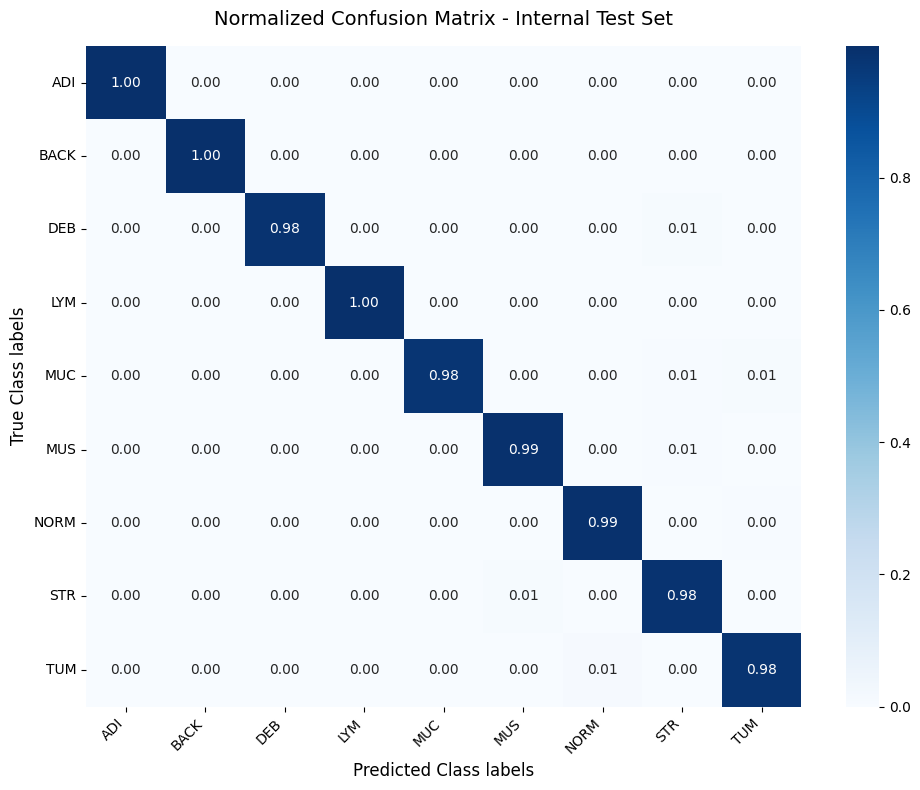

Confusion matrix generated and saved as 'internal_test_confusion_matrix.png'.


In [14]:
#internal test set confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Calculate the raw confusion matrix
cm = confusion_matrix(internal_labels, internal_preds)

# 2. Normalize the matrix by row (shows the percentage of correct predictions per class)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 3. Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap="Blues", 
    xticklabels=class_names, 
    yticklabels=class_names
)

plt.title("Normalized Confusion Matrix - Internal Test Set", fontsize=14, pad=15)
plt.ylabel("True Class labels", fontsize=12)
plt.xlabel("Predicted Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the figure to your Kaggle output directory
plt.savefig("internal_test_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion matrix generated and saved as 'internal_test_confusion_matrix.png'.")



In [15]:
#external test

import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Path to your external clinic dataset (verified next to your 100K data)
external_dir = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/CRC-VAL-HE-7K/CRC-VAL-HE-7K"

# 2. Match the exact base transforms used for the baseline model
external_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Load the external dataset
external_dataset = datasets.ImageFolder(root=external_dir, transform=external_transform)

# 4. Optimized DataLoader (using the same 4 workers and pinned memory)
external_loader = DataLoader(
    external_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)

print(f"Loaded external clinic test set: {len(external_dataset)} images found.")
print(f"Verifying external classes match: {external_dataset.classes}")

# 5. Run evaluation using the function we built earlier
print("\nEvaluating baseline model on External Test Set (7K)...")
external_labels, external_preds = evaluate_model(model, external_loader, device)

# 6. Print the External Academic Classification Report
print("\n================ EXTERNAL CLINIC TEST SET REPORT ================")
print(classification_report(external_labels, external_preds, target_names=external_dataset.classes, digits=4))



Loaded external clinic test set: 7180 images found.
Verifying external classes match: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']

Evaluating baseline model on External Test Set (7K)...

================ EXTERNAL CLINIC TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     0.9915    0.6129    0.7575      1338
        BACK     0.9906    1.0000    0.9953       847
         DEB     0.9114    0.9705    0.9400       339
         LYM     0.9724    1.0000    0.9860       634
         MUC     0.9444    0.9691    0.9566      1035
         MUS     0.4710    0.8784    0.6132       592
        NORM     0.9327    0.9730    0.9524       741
         STR     0.9748    0.5511    0.7041       421
         TUM     0.9197    0.9757    0.9469      1233

    accuracy                         0.8787      7180
   macro avg     0.9010    0.8812    0.8724      7180
weighted avg     0.9169    0.8787    0.8807      7180



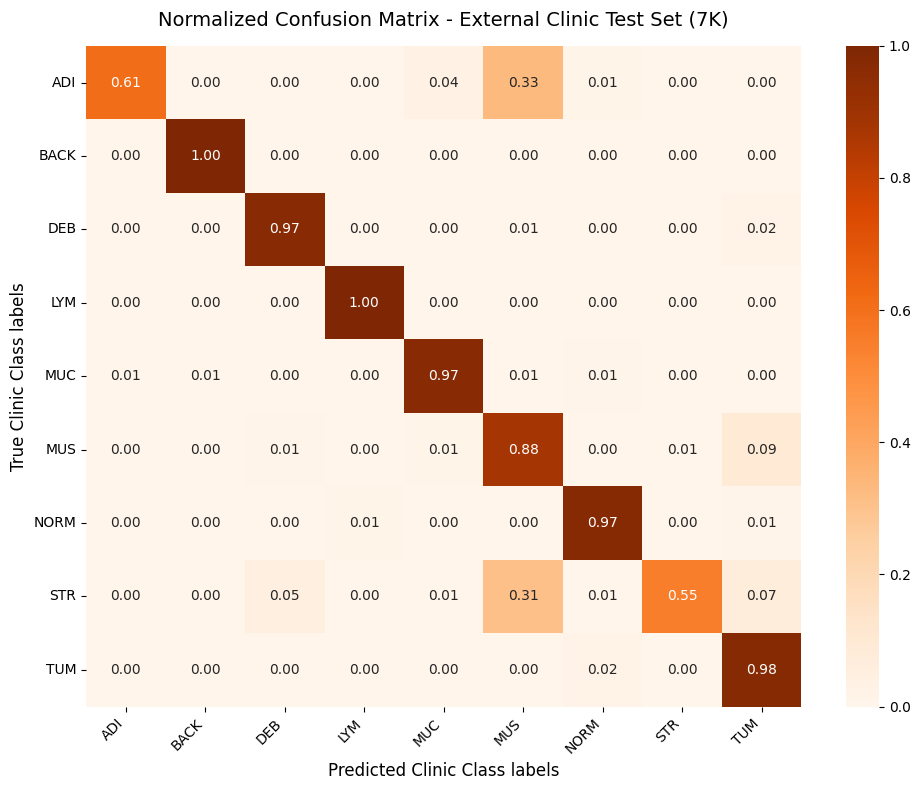

External confusion matrix generated and saved as 'external_test_confusion_matrix.png'.


In [16]:
#Confusion matrix- external set

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Calculate the raw external confusion matrix
cm_ext = confusion_matrix(external_labels, external_preds)

# 2. Normalize by row to show percentage performance per class
cm_ext_normalized = cm_ext.astype('float') / cm_ext.sum(axis=1)[:, np.newaxis]

# 3. Plot the external heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_ext_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap="Oranges", # Using a different color to easily tell internal vs external apart
    xticklabels=external_dataset.classes, 
    yticklabels=external_dataset.classes
)

plt.title("Normalized Confusion Matrix - External Clinic Test Set (7K)", fontsize=14, pad=15)
plt.ylabel("True Clinic Class labels", fontsize=12)
plt.xlabel("Predicted Clinic Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the figure to your Kaggle output directory
plt.savefig("external_test_confusion_matrix.png", dpi=300)
plt.show()

print("External confusion matrix generated and saved as 'external_test_confusion_matrix.png'.")


In [17]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, random_split

# ==========================================
# 1. SETUP SPATIAL AUGMENTATIONS ONLY
# ==========================================
# Train transforms include spatial alterations but NO color/stain adjustments
spatial_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=90), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation and Test transforms remain identical to baseline (unaltered)
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ==========================================
# 2. DATASETS & SPLIT REPLICATION
# ==========================================
base_path = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"
nct_dir = os.path.join(base_path, "NCT-CRC-HE-100K/NCT-CRC-HE-100K")

BATCH_SIZE = 32
TOTAL_EPOCHS = 30
CHECKPOINT_INTERVAL = 5

# Re-load dataset with the spatial augmentation transforms applied
train_dataset_augmented = datasets.ImageFolder(root=nct_dir, transform=spatial_train_transform)
val_dataset_eval = datasets.ImageFolder(root=nct_dir, transform=eval_transform)
test_dataset_eval = datasets.ImageFolder(root=nct_dir, transform=eval_transform)

total_len = len(train_dataset_augmented)
train_size = int(0.70 * total_len)
val_size = int(0.15 * total_len)
test_size = total_len - train_size - val_size

# Use the EXACT same seed (42) to ensure the images in each split match the baseline perfectly
train_dataset, _ , _ = random_split(train_dataset_augmented, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))
_, val_dataset, _ = random_split(val_dataset_eval, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))
_, _, test_loader_dataset = random_split(test_dataset_eval, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))

# Optimized DataLoaders with 4 workers and memory pinning
spatial_train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
spatial_val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
spatial_test_loader = DataLoader(test_loader_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f"Spatial-Only Model Data Prepared:")
print(f"  → Augmented Train samples: {len(train_dataset)}")

# ==========================================
# 3. TRAINING ROUTINE
# ==========================================
# Initialize a brand new ResNet50 from scratch
model_spatial = models.resnet50(weights=None)
model_spatial.fc = nn.Linear(model_spatial.fc.in_features, 9)
model_spatial = model_spatial.to(device) # Reuses 'device' variable from earlier check

#criterion = nn.CrossEntropyLoss()
#optimizer = optim.Adam(model_spatial.parameters(), lr=1e-3)

#print(f"\nStarting training loop for Spatial-Only model ({TOTAL_EPOCHS} epochs)...")
#for epoch in range(TOTAL_EPOCHS):
    #model_spatial.train()
    #running_loss = 0.0
    #for inputs, labels in spatial_train_loader:
        #inputs, labels = inputs.to(device), labels.to(device)
        
        #optimizer.zero_grad()
        #outputs = model_spatial(inputs)
        #loss = criterion(outputs, labels)
        #loss.backward()
        #optimizer.step()
        
        #running_loss += loss.item() * inputs.size(0)
        
    #epoch_loss = running_loss / len(spatial_train_loader.dataset)
    
    # Validation Check
    #model_spatial.eval()
    #correct = 0
    #with torch.no_grad():
        #for inputs, labels in spatial_val_loader:
            #inputs, labels = inputs.to(device), labels.to(device)
            #outputs = model_spatial(inputs)
            #_, preds = torch.max(outputs, 1)
            #correct += torch.sum(preds == labels.data)
            
    #val_accuracy = correct.double() / len(spatial_val_loader.dataset)
    #print(f"Epoch {epoch+1}/{TOTAL_EPOCHS} | Train Loss: {epoch_loss:.4f} | Val Accuracy: {val_accuracy:.4f}")
    
    # Checkpoints
    #if (epoch + 1) % CHECKPOINT_INTERVAL == 0:
        #checkpoint_name = f"resnet50_spatial_epoch_{epoch+1}.pth"
        #torch.save(model_spatial.state_dict(), checkpoint_name)
        #print(f"--- Checkpoint saved: {checkpoint_name} ---")

# Save final spatial model weights
#torch.save(model_spatial.state_dict(), "resnet50_spatial_only.pth")
#print("\nTraining complete! Spatial-only model saved as 'resnet50_spatial_only.pth'.")


Spatial-Only Model Data Prepared:
  → Augmented Train samples: 70000


Spatial-Only model weights loaded successfully.
Evaluating Spatial-Only model on Internal Test Set...

================ SPATIAL-ONLY: INTERNAL TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     0.9969    0.9919    0.9944      1613
        BACK     0.9924    0.9994    0.9959      1575
         DEB     0.9954    0.9813    0.9883      1765
         LYM     0.9947    0.9994    0.9970      1684
         MUC     0.9923    0.9900    0.9911      1297
         MUS     0.9985    0.9689    0.9835      2056
        NORM     0.9931    0.9885    0.9908      1303
         STR     0.9508    0.9905    0.9702      1579
         TUM     0.9865    0.9948    0.9906      2128

    accuracy                         0.9889     15000
   macro avg     0.9889    0.9894    0.9891     15000
weighted avg     0.9892    0.9889    0.9890     15000



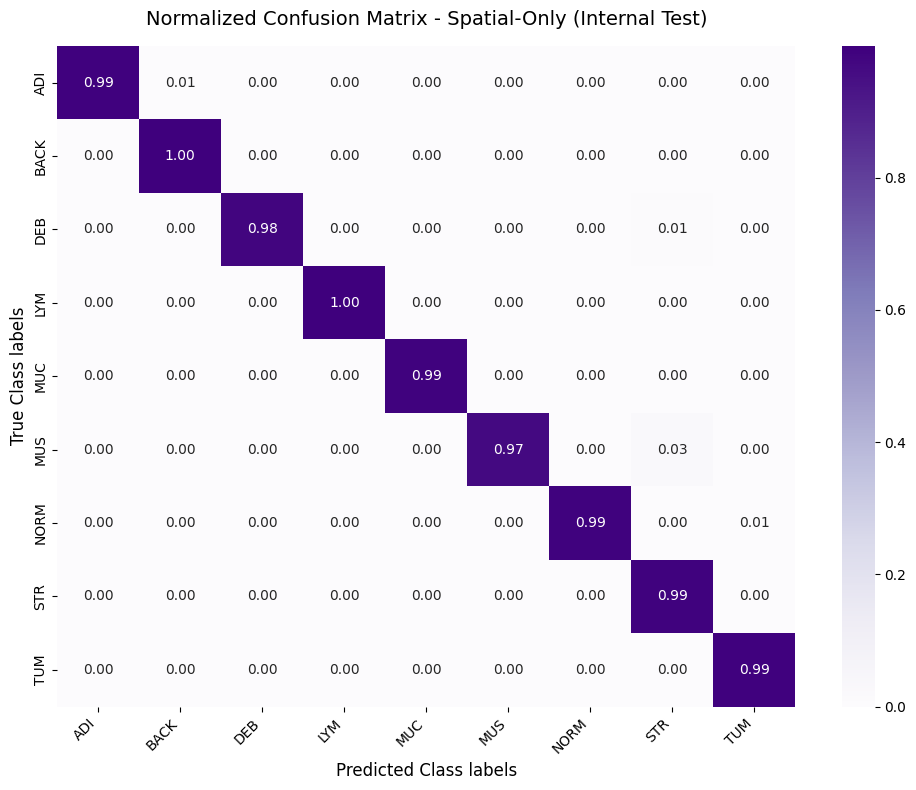


Evaluating Spatial-Only model on External Test Set (7K)...

================ SPATIAL-ONLY: EXTERNAL CLINIC TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     0.9856    0.9215    0.9525      1338
        BACK     0.9976    1.0000    0.9988       847
         DEB     0.8768    0.9233    0.8994       339
         LYM     0.8980    1.0000    0.9463       634
         MUC     0.9763    0.9546    0.9653      1035
         MUS     0.7517    0.7517    0.7517       592
        NORM     0.9613    0.9717    0.9664       741
         STR     0.7402    0.7173    0.7286       421
         TUM     0.9634    0.9813    0.9723      1233

    accuracy                         0.9320      7180
   macro avg     0.9057    0.9135    0.9090      7180
weighted avg     0.9328    0.9320    0.9319      7180



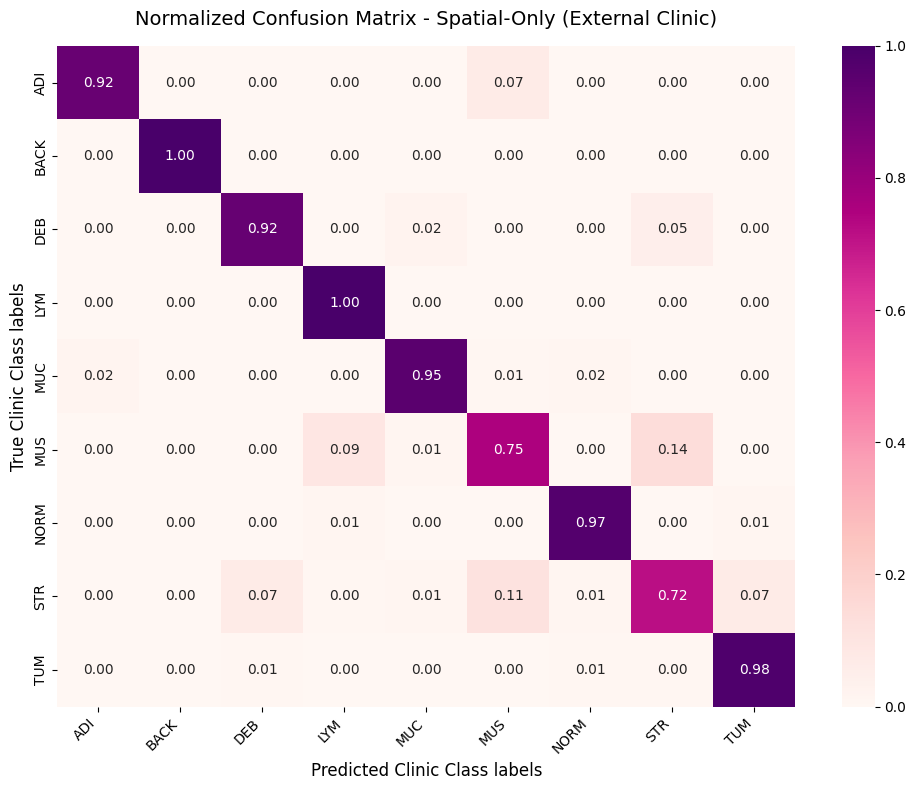

In [18]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from sklearn.metrics import classification_report, confusion_matrix

# 1. Verification function for evaluation (re-used for consistency)
def evaluate_model(model, data_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)

# 2. Load the trained Spatial-Only model weights
weights_path = "/kaggle/input/datasets/koushiki123890567/spatial-only-weights/resnet50_spatial_only.pth"
model_spatial.load_state_dict(torch.load(weights_path, map_location=device))
print("Spatial-Only model weights loaded successfully.")

# 3. Evaluate on the isolated Internal Test Set
print("Evaluating Spatial-Only model on Internal Test Set...")
spatial_internal_labels, spatial_internal_preds = evaluate_model(model_spatial, spatial_test_loader, device)

# 4. Print the Internal Classification Report
class_names = dataset.classes
print("\n================ SPATIAL-ONLY: INTERNAL TEST SET REPORT ================")
print(classification_report(spatial_internal_labels, spatial_internal_preds, target_names=class_names, digits=4))

# 5. Plot the Normalized Internal Confusion Matrix
cm_spatial_int = confusion_matrix(spatial_internal_labels, spatial_internal_preds)
cm_spatial_int_norm = cm_spatial_int.astype('float') / cm_spatial_int.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_spatial_int_norm, annot=True, fmt=".2f", cmap="Purples", xticklabels=class_names, yticklabels=class_names)
plt.title("Normalized Confusion Matrix - Spatial-Only (Internal Test)", fontsize=14, pad=15)
plt.ylabel("True Class labels", fontsize=12)
plt.xlabel("Predicted Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("spatial_only_internal_confusion_matrix.png", dpi=300)
plt.show()

# ==========================================
# EXTERNAL CLINIC DATASET EVALUATION (7K)
# ==========================================
# Setup the external loader again to ensure consistency
external_dir = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/CRC-VAL-HE-7K/CRC-VAL-HE-7K"
external_dataset = datasets.ImageFolder(root=external_dir, transform=eval_transform)
external_loader = DataLoader(external_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("\nEvaluating Spatial-Only model on External Test Set (7K)...")
spatial_ext_labels, spatial_ext_preds = evaluate_model(model_spatial, external_loader, device)

# 6. Print the External Classification Report
print("\n================ SPATIAL-ONLY: EXTERNAL CLINIC TEST SET REPORT ================")
print(classification_report(spatial_ext_labels, spatial_ext_preds, target_names=external_dataset.classes, digits=4))

# 7. Plot the Normalized External Confusion Matrix
cm_spatial_ext = confusion_matrix(spatial_ext_labels, spatial_ext_preds)
cm_spatial_ext_norm = cm_spatial_ext.astype('float') / cm_spatial_ext.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_spatial_ext_norm, 
    annot=True, 
    fmt=".2f", 
    cmap=cm.RdPu, 
    xticklabels=external_dataset.classes, 
    yticklabels=external_dataset.classes
)
plt.title("Normalized Confusion Matrix - Spatial-Only (External Clinic)", fontsize=14, pad=15)
plt.ylabel("True Clinic Class labels", fontsize=12)
plt.xlabel("Predicted Clinic Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("spatial_only_external_confusion_matrix.png", dpi=300)
plt.show()


In [19]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, random_split

# ==========================================
# 0. ENVIRONMENT DEVICE CONFIGURATION
# ==========================================
# This line prevents the NameError: name 'device' is not defined crash
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using execution device: {device}")

# ==========================================
# 1. SETUP STAIN AUGMENTATIONS ONLY
# ==========================================
# Train transforms include color/stain alterations but NO spatial changes
stain_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    # ColorJitter simulates H&E stain variations across different labs
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation and Test transforms remain identical to baseline (unaltered)
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ==========================================
# 2. DATASETS & SPLIT REPLICATION
# ==========================================
base_path = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"
nct_dir = os.path.join(base_path, "NCT-CRC-HE-100K/NCT-CRC-HE-100K")

BATCH_SIZE = 32
TOTAL_EPOCHS = 30
CHECKPOINT_INTERVAL = 5

# Load dataset with the stain augmentation transforms applied
train_dataset_augmented = datasets.ImageFolder(root=nct_dir, transform=stain_train_transform)
val_dataset_eval = datasets.ImageFolder(root=nct_dir, transform=eval_transform)
test_dataset_eval = datasets.ImageFolder(root=nct_dir, transform=eval_transform)

total_len = len(train_dataset_augmented)
train_size = int(0.70 * total_len)
val_size = int(0.15 * total_len)
test_size = total_len - train_size - val_size

# Replicate the exact split using seed 42
train_dataset, _ , _ = random_split(train_dataset_augmented, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))
_, val_dataset, _ = random_split(val_dataset_eval, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))
_, _, test_loader_dataset = random_split(test_dataset_eval, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))

# Optimized DataLoaders
stain_train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
stain_val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
stain_test_loader = DataLoader(test_loader_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f"Stain-Only Model Data Prepared:")
print(f"  → Augmented Train samples: {len(train_dataset)}")

# ==========================================
# 3. TRAINING ROUTINE
# ==========================================
# Initialize a brand new ResNet50 from scratch
model_stain = models.resnet50(weights=None)
model_stain.fc = nn.Linear(model_stain.fc.in_features, 9)
model_stain = model_stain.to(device)

#criterion = nn.CrossEntropyLoss()
#optimizer = optim.Adam(model_stain.parameters(), lr=1e-3)

#print(f"\nStarting training loop for Stain-Only model ({TOTAL_EPOCHS} epochs)...")
#for epoch in range(TOTAL_EPOCHS):
    #model_stain.train()
    #running_loss = 0.0
    #for inputs, labels in stain_train_loader:
        #inputs, labels = inputs.to(device), labels.to(device)
        
        #optimizer.zero_grad()
        #outputs = model_stain(inputs)
        #loss = criterion(outputs, labels)
        #loss.backward()
        #optimizer.step()
        
        #running_loss += loss.item() * inputs.size(0)
        
    #epoch_loss = running_loss / len(stain_train_loader.dataset)
    
    # Validation Check
    #model_stain.eval()
    #correct = 0
    #with torch.no_grad():
        #for inputs, labels in stain_val_loader:
            #inputs, labels = inputs.to(device), labels.to(device)
            #outputs = model_stain(inputs)
            #_, preds = torch.max(outputs, 1)
            #correct += torch.sum(preds == labels.data)
            
    #val_accuracy = correct.double() / len(stain_val_loader.dataset)
    #print(f"Epoch {epoch+1}/{TOTAL_EPOCHS} | Train Loss: {epoch_loss:.4f} | Val Accuracy: {val_accuracy:.4f}")
    
    # Checkpoints
    #if (epoch + 1) % CHECKPOINT_INTERVAL == 0:
        #checkpoint_name = f"resnet50_stain_epoch_{epoch+1}.pth"
        #torch.save(model_stain.state_dict(), checkpoint_name)
        #print(f"--- Checkpoint saved: {checkpoint_name} ---")

# Save final stain model weights
#torch.save(model_stain.state_dict(), "resnet50_stain_only.pth")
#print("\nTraining complete! Stain-only model saved as 'resnet50_stain_only.pth'.")


Using execution device: cuda
Stain-Only Model Data Prepared:
  → Augmented Train samples: 70000


Stain-Only model weights loaded successfully.
Evaluating Stain-Only model on Internal Test Set...

================ STAIN-ONLY: INTERNAL TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     0.9950    0.9926    0.9938      1613
        BACK     0.9968    0.9987    0.9978      1575
         DEB     0.9880    0.9836    0.9858      1765
         LYM     0.9988    0.9970    0.9979      1684
         MUC     0.9642    0.9761    0.9701      1297
         MUS     0.9896    0.9674    0.9784      2056
        NORM     0.9852    0.9716    0.9784      1303
         STR     0.9452    0.9715    0.9582      1579
         TUM     0.9762    0.9836    0.9799      2128

    accuracy                         0.9825     15000
   macro avg     0.9821    0.9825    0.9822     15000
weighted avg     0.9826    0.9825    0.9825     15000



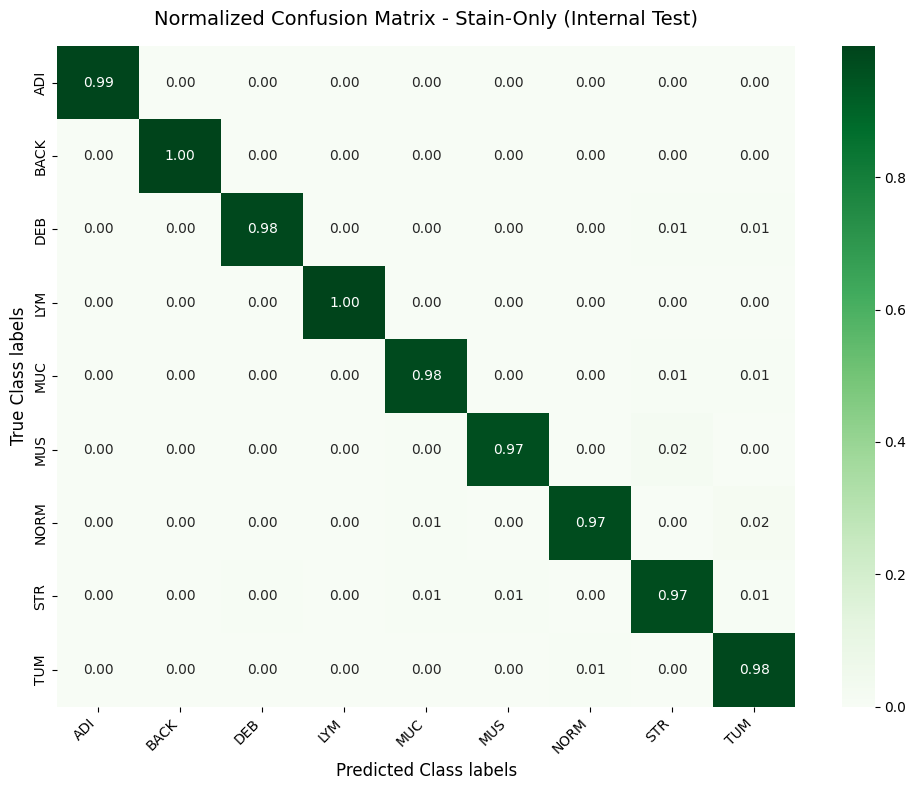


Evaluating Stain-Only model on External Test Set (7K)...

================ STAIN-ONLY: EXTERNAL CLINIC TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     0.9992    0.8879    0.9402      1338
        BACK     1.0000    1.0000    1.0000       847
         DEB     0.9297    0.8968    0.9129       339
         LYM     0.9937    0.9953    0.9945       634
         MUC     0.8806    0.9981    0.9357      1035
         MUS     0.7721    0.8412    0.8052       592
        NORM     0.9518    0.9852    0.9682       741
         STR     0.7603    0.7007    0.7293       421
         TUM     0.9884    0.9692    0.9787      1233

    accuracy                         0.9361      7180
   macro avg     0.9195    0.9194    0.9183      7180
weighted avg     0.9389    0.9361    0.9361      7180



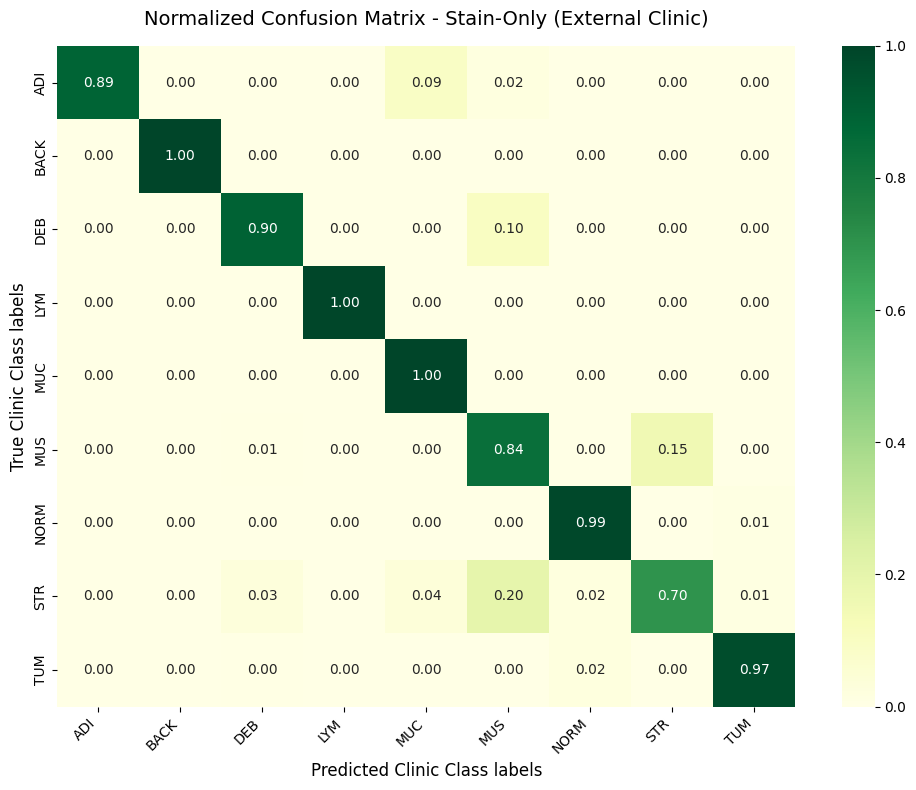

In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from torchvision import datasets
from sklearn.metrics import classification_report, confusion_matrix

# 1. Verification function for evaluation (re-used for consistency)
def evaluate_model(model, data_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)

# 2. Load the trained Stain-Only model weights
weights_path = "/kaggle/input/datasets/koushiki123890567/stain-only-weights/resnet50_stain_only.pth"
model_stain.load_state_dict(torch.load(weights_path, map_location=device))
print("Stain-Only model weights loaded successfully.")

# 3. Evaluate on the isolated Internal Test Set
print("Evaluating Stain-Only model on Internal Test Set...")
stain_internal_labels, stain_internal_preds = evaluate_model(model_stain, stain_test_loader, device)

# 4. Print the Internal Classification Report
class_names = dataset.classes
print("\n================ STAIN-ONLY: INTERNAL TEST SET REPORT ================")
print(classification_report(stain_internal_labels, stain_internal_preds, target_names=class_names, digits=4))

# 5. Plot the Normalized Internal Confusion Matrix
cm_stain_int = confusion_matrix(stain_internal_labels, stain_internal_preds)
cm_stain_int_norm = cm_stain_int.astype('float') / cm_stain_int.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_stain_int_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
plt.title("Normalized Confusion Matrix - Stain-Only (Internal Test)", fontsize=14, pad=15)
plt.ylabel("True Class labels", fontsize=12)
plt.xlabel("Predicted Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("stain_only_internal_confusion_matrix.png", dpi=300)
plt.show()

# ==========================================
# EXTERNAL CLINIC DATASET EVALUATION (7K)
# ==========================================
external_dir = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/CRC-VAL-HE-7K/CRC-VAL-HE-7K"
external_dataset = datasets.ImageFolder(root=external_dir, transform=eval_transform)
external_loader = DataLoader(external_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("\nEvaluating Stain-Only model on External Test Set (7K)...")
stain_ext_labels, stain_ext_preds = evaluate_model(model_stain, external_loader, device)

# 6. Print the External Classification Report
print("\n================ STAIN-ONLY: EXTERNAL CLINIC TEST SET REPORT ================")
print(classification_report(stain_ext_labels, stain_ext_preds, target_names=external_dataset.classes, digits=4))

# 7. Plot the Normalized External Confusion Matrix
cm_stain_ext = confusion_matrix(stain_ext_labels, stain_ext_preds)
cm_stain_ext_norm = cm_stain_ext.astype('float') / cm_stain_ext.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_stain_ext_norm, annot=True, fmt=".2f", cmap="YlGn", xticklabels=external_dataset.classes, yticklabels=external_dataset.classes)
plt.title("Normalized Confusion Matrix - Stain-Only (External Clinic)", fontsize=14, pad=15)
plt.ylabel("True Clinic Class labels", fontsize=12)
plt.xlabel("Predicted Clinic Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("stain_only_external_confusion_matrix.png", dpi=300)
plt.show()


In [21]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, random_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using execution device: {device}")
# ==========================================
# 1. SETUP COMBINED AUGMENTATIONS
# ==========================================
# Train transforms combine BOTH spatial and stain alterations
combined_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    # Spatial components
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=90), 
    # Stain component
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation and Test transforms remain identical to baseline (unaltered)
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ==========================================
# 2. DATASETS & SPLIT REPLICATION
# ==========================================
base_path = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"
nct_dir = os.path.join(base_path, "NCT-CRC-HE-100K/NCT-CRC-HE-100K")

BATCH_SIZE = 32
TOTAL_EPOCHS = 30
CHECKPOINT_INTERVAL = 5

# Load dataset with combined augmentation transforms applied
train_dataset_augmented = datasets.ImageFolder(root=nct_dir, transform=combined_train_transform)
val_dataset_eval = datasets.ImageFolder(root=nct_dir, transform=eval_transform)
test_dataset_eval = datasets.ImageFolder(root=nct_dir, transform=eval_transform)

total_len = len(train_dataset_augmented)
train_size = int(0.70 * total_len)
val_size = int(0.15 * total_len)
test_size = total_len - train_size - val_size

# Replicate the exact split using seed 42
train_dataset, _ , _ = random_split(train_dataset_augmented, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))
_, val_dataset, _ = random_split(val_dataset_eval, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))
_, _, test_loader_dataset = random_split(test_dataset_eval, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42))

# Optimized DataLoaders
combined_train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
combined_val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
combined_test_loader = DataLoader(test_loader_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f"Combined Model Data Prepared:")
print(f"  → Augmented Train samples: {len(train_dataset)}")

# ==========================================
# 3. TRAINING ROUTINE
# ==========================================
# Initialize a brand new ResNet50 from scratch
model_combined = models.resnet50(weights=None)
model_combined.fc = nn.Linear(model_combined.fc.in_features, 9)
model_combined = model_combined.to(device)

#criterion = nn.CrossEntropyLoss()
#optimizer = optim.Adam(model_combined.parameters(), lr=1e-3)

#print(f"\nStarting training loop for Combined model ({TOTAL_EPOCHS} epochs)...")
#for epoch in range(TOTAL_EPOCHS):
    #model_combined.train()
    #running_loss = 0.0
    #for inputs, labels in combined_train_loader:
        #inputs, labels = inputs.to(device), labels.to(device)
        
        #optimizer.zero_grad()
        #outputs = model_combined(inputs)
        #loss = criterion(outputs, labels)
        #loss.backward()
        #optimizer.step()
        
        #running_loss += loss.item() * inputs.size(0)
        
    #epoch_loss = running_loss / len(combined_train_loader.dataset)
    
    # Validation Check
    #model_combined.eval()
    #correct = 0
    #with torch.no_grad():
        #for inputs, labels in combined_val_loader:
            #inputs, labels = inputs.to(device), labels.to(device)
            #outputs = model_combined(inputs)
            #_, preds = torch.max(outputs, 1)
            #correct += torch.sum(preds == labels.data)
            
    #val_accuracy = correct.double() / len(combined_val_loader.dataset)
    #print(f"Epoch {epoch+1}/{TOTAL_EPOCHS} | Train Loss: {epoch_loss:.4f} | Val Accuracy: {val_accuracy:.4f}")
    
    # Checkpoints
    #if (epoch + 1) % CHECKPOINT_INTERVAL == 0:
        #checkpoint_name = f"resnet50_combined_epoch_{epoch+1}.pth"
        #torch.save(model_combined.state_dict(), checkpoint_name)
        #print(f"--- Checkpoint saved: {checkpoint_name} ---")

# Save final combined model weights
#torch.save(model_combined.state_dict(), "resnet50_combined.pth")
#print("\nTraining complete! Combined model saved as 'resnet50_combined.pth'.")


Using execution device: cuda
Combined Model Data Prepared:
  → Augmented Train samples: 70000


Combined model weights loaded successfully.
Evaluating Combined model on Internal Test Set...

================ COMBINED MODEL: INTERNAL TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     0.9994    0.9950    0.9972      1613
        BACK     0.9959    0.9352    0.9646      1575
         DEB     0.9861    0.9229    0.9535      1765
         LYM     0.9841    0.9947    0.9894      1684
         MUC     0.9733    0.9854    0.9793      1297
         MUS     0.9831    0.9917    0.9874      2056
        NORM     0.9809    0.9877    0.9843      1303
         STR     0.9810    0.9506    0.9656      1579
         TUM     0.9009    0.9873    0.9422      2128

    accuracy                         0.9725     15000
   macro avg     0.9761    0.9723    0.9737     15000
weighted avg     0.9738    0.9725    0.9726     15000



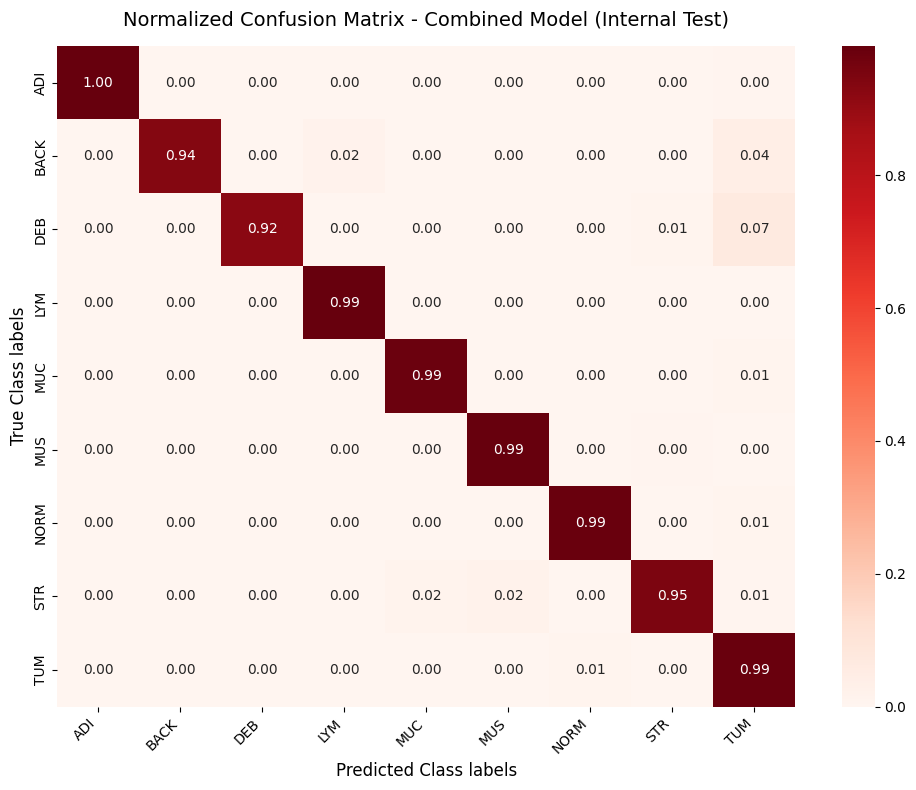


Evaluating Combined model on External Test Set (7K)...

================ COMBINED MODEL: EXTERNAL CLINIC TEST SET REPORT ================
              precision    recall  f1-score   support

         ADI     0.9853    0.9507    0.9677      1338
        BACK     0.9988    0.9953    0.9970       847
         DEB     0.7949    0.9263    0.8556       339
         LYM     0.9966    0.9322    0.9633       634
         MUC     0.9165    0.9758    0.9453      1035
         MUS     0.8608    0.7314    0.7909       592
        NORM     0.9204    0.9825    0.9504       741
         STR     0.7007    0.7173    0.7089       421
         TUM     0.9642    0.9619    0.9631      1233

    accuracy                         0.9302      7180
   macro avg     0.9043    0.9081    0.9047      7180
weighted avg     0.9317    0.9302    0.9299      7180



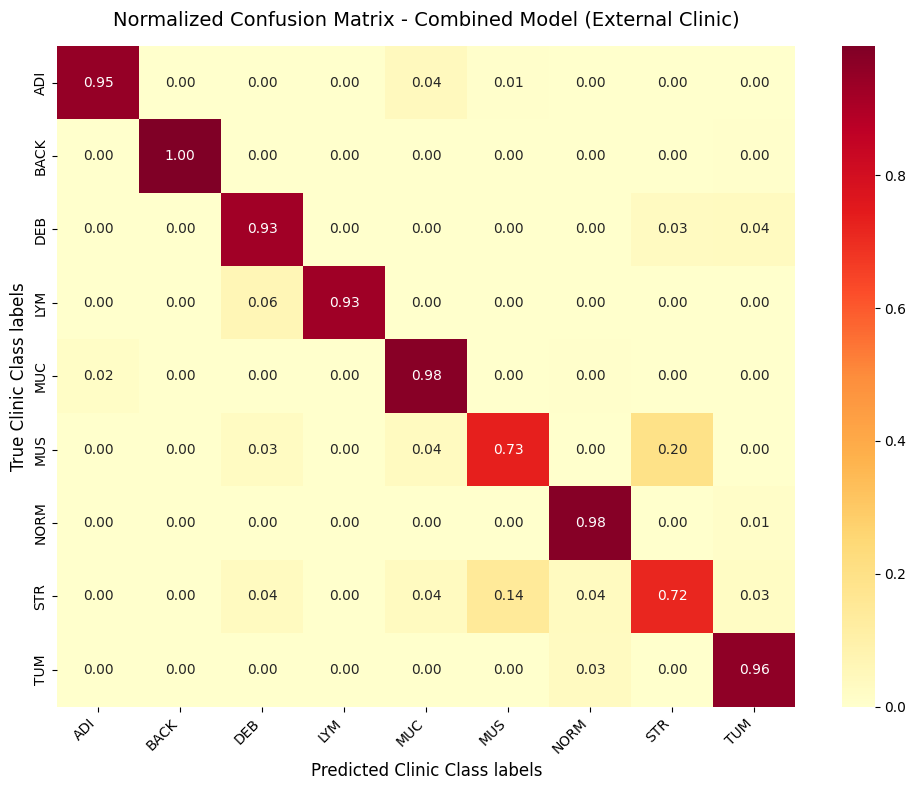

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from torchvision import datasets
from sklearn.metrics import classification_report, confusion_matrix

# 1. Verification function for evaluation (re-used for consistency)
def evaluate_model(model, data_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)

# 2. Load the trained Combined model weights
weights_path = "/kaggle/input/datasets/koushiki123890567/resnet50-combined-augmentation-weights/resnet50_combined.pth"
model_combined.load_state_dict(torch.load(weights_path, map_location=device))
print("Combined model weights loaded successfully.")

# 3. Evaluate on the isolated Internal Test Set
print("Evaluating Combined model on Internal Test Set...")
combined_internal_labels, combined_internal_preds = evaluate_model(model_combined, combined_test_loader, device)

# 4. Print the Internal Classification Report
class_names = dataset.classes
print("\n================ COMBINED MODEL: INTERNAL TEST SET REPORT ================")
print(classification_report(combined_internal_labels, combined_internal_preds, target_names=class_names, digits=4))

# 5. Plot the Normalized Internal Confusion Matrix
cm_comb_int = confusion_matrix(combined_internal_labels, combined_internal_preds)
cm_comb_int_norm = cm_comb_int.astype('float') / cm_comb_int.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_comb_int_norm, annot=True, fmt=".2f", cmap="Reds", xticklabels=class_names, yticklabels=class_names)
plt.title("Normalized Confusion Matrix - Combined Model (Internal Test)", fontsize=14, pad=15)
plt.ylabel("True Class labels", fontsize=12)
plt.xlabel("Predicted Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("combined_internal_confusion_matrix.png", dpi=300)
plt.show()

# ==========================================
# EXTERNAL CLINIC DATASET EVALUATION (7K)
# ==========================================
external_dir = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology/CRC-VAL-HE-7K/CRC-VAL-HE-7K"
external_dataset = datasets.ImageFolder(root=external_dir, transform=eval_transform)
external_loader = DataLoader(external_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("\nEvaluating Combined model on External Test Set (7K)...")
combined_ext_labels, combined_ext_preds = evaluate_model(model_combined, external_loader, device)

# 6. Print the External Classification Report
print("\n================ COMBINED MODEL: EXTERNAL CLINIC TEST SET REPORT ================")
print(classification_report(combined_ext_labels, combined_ext_preds, target_names=external_dataset.classes, digits=4))

# 7. Plot the Normalized External Confusion Matrix
cm_comb_ext = confusion_matrix(combined_ext_labels, combined_ext_preds)
cm_comb_ext_norm = cm_comb_ext.astype('float') / cm_comb_ext.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_comb_ext_norm, annot=True, fmt=".2f", cmap="YlOrRd", xticklabels=external_dataset.classes, yticklabels=external_dataset.classes)
plt.title("Normalized Confusion Matrix - Combined Model (External Clinic)", fontsize=14, pad=15)
plt.ylabel("True Clinic Class labels", fontsize=12)
plt.xlabel("Predicted Clinic Class labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("combined_external_confusion_matrix.png", dpi=300)
plt.show()
